# Task 6: MACE dataset of CH4 in IRMOF-1

The data was generated on the UGent HPC (joltik, V100) with `hpc/make_dataset.py` and the functions in `src/mace_dataset.py`:

- 4000 random positions uniform in the empty cell (seed 6); positions with a baseline energy > 10,000 K are skipped (CH4 on a framework atom).
- Per point an all-atom CH4 with a uniformly random orientation (quaternion) and the C atom exactly on the point.
- E_int = E(framework + CH4) − E(framework) − E(CH4 alone) with MACE-MP-0 medium + D3 (float64), converted to K.
- References: E(framework) = −2834.1587 eV, E(CH4 alone) = −23.9450 eV. Cost: ~0.3 s per point.

The CSV file `data/mace_dataset_irmof1_ch4.csv` is committed, so task 7 runs without a GPU.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt("../data/mace_dataset_irmof1_ch4.csv", delimiter=",", names=True)
E_base = data["E_baseline_K"]
E_mace = data["E_mace_K"]
K_TO_KJMOL = 1 / 120.27
print(len(data), "points, columns:", data.dtype.names)
for name, E in (("baseline", E_base), ("MACE", E_mace)):
    print(f"{name:9s} [kJ/mol]: min {E.min() * K_TO_KJMOL:7.1f}  median {np.median(E) * K_TO_KJMOL:7.1f}  max {E.max() * K_TO_KJMOL:8.1f}")

4000 points, columns: ('x', 'y', 'z', 'qw', 'qx', 'qy', 'qz', 'E_baseline_K', 'E_mace_K')
baseline  [kJ/mol]: min   -13.9  median    -4.0  max     83.1
MACE      [kJ/mol]: min   -29.9  median    -4.0  max     82.9


## Check: histogram of E_MACE and comparison with the baseline

Expectation from the task list: bulk around −10 to −20 kJ/mol (−1200 to −2400 K), tail towards positive. If baseline and MACE do not correlate, the placement or the unit is wrong.

fraction E_MACE < 0: 0.91   (baseline: 0.82)
minimum E_MACE: -29.9 kJ/mol, minimum baseline: -13.9 kJ/mol
median E_MACE (E<0): -4.6 kJ/mol, baseline (E<0): -4.7 kJ/mol
correlation (E_baseline < 25 kJ/mol): 0.448


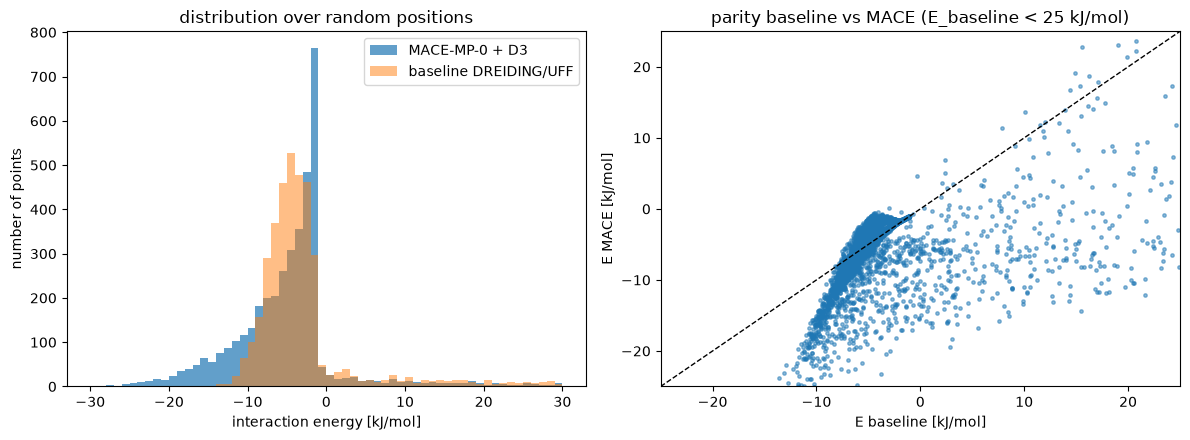

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
bins = np.linspace(-30, 30, 61)
ax1.hist(E_mace * K_TO_KJMOL, bins=bins, alpha=0.7, label="MACE-MP-0 + D3")
ax1.hist(E_base * K_TO_KJMOL, bins=bins, alpha=0.5, label="baseline DREIDING/UFF")
ax1.set_xlabel("interaction energy [kJ/mol]")
ax1.set_ylabel("number of points")
ax1.legend()
ax1.set_title("distribution over random positions")

m = (E_base < 3000)
ax2.scatter(E_base[m] * K_TO_KJMOL, E_mace[m] * K_TO_KJMOL, s=6, alpha=0.5)
lim = [-25, 25]
ax2.plot(lim, lim, "k--", lw=1)
ax2.set_xlim(lim); ax2.set_ylim(lim)
ax2.set_xlabel("E baseline [kJ/mol]")
ax2.set_ylabel("E MACE [kJ/mol]")
ax2.set_title("parity baseline vs MACE (E_baseline < 25 kJ/mol)")
fig.tight_layout()
fig.savefig("../results/mace_dataset_overview.png", dpi=150)

neg = E_mace < 0
print(f"fraction E_MACE < 0: {neg.mean():.2f}   (baseline: {(E_base < 0).mean():.2f})")
print(f"minimum E_MACE: {E_mace.min() * K_TO_KJMOL:.1f} kJ/mol, minimum baseline: {E_base.min() * K_TO_KJMOL:.1f} kJ/mol")
print(f"median E_MACE (E<0): {np.median(E_mace[neg]) * K_TO_KJMOL:.1f} kJ/mol, baseline (E<0): {np.median(E_base[E_base < 0]) * K_TO_KJMOL:.1f} kJ/mol")
print(f"correlation (E_baseline < 25 kJ/mol): {np.corrcoef(E_base[m], E_mace[m])[0, 1]:.3f}")

## Widom with MACE directly on the dataset

Because the positions are uniform, ⟨exp(−E/T)⟩ over the dataset is a Widom estimate with MACE as the force field. The skipped overlaps contribute exp(−E/T) ≈ 0, so they count in the denominator with zero in the numerator. This gives K_H(MACE) for the table in task 7.

In [3]:
import sys
sys.path.insert(0, "../src")
from energy import load_framework
from widom import rho_framework, henry_coefficient

positions, symbols, L, masses = load_framework("../data/IRMOF-1.cif")
rho_fw = rho_framework(masses, L)
T = 298.0
n_skipped = 3153  # from the Slurm output of make_dataset.py
n_total = len(data) + n_skipped

def widom_from_dataset(E_K, n_total, T, n_blocks=10):
    b = np.exp(-np.asarray(E_K) / T)
    # add the overlaps as zeros, then blocks
    b = np.concatenate([b, np.zeros(n_total - len(b))])
    rng = np.random.default_rng(0)
    rng.shuffle(b)
    n = len(b) // n_blocks * n_blocks
    blocks = b[:n].reshape(n_blocks, -1).mean(axis=1)
    return blocks.mean(), blocks.std(ddof=1) / np.sqrt(n_blocks)

for name, col in (("baseline", E_base), ("MACE", E_mace)):
    bm, sem = widom_from_dataset(col, n_total, T)
    print(f"{name:9s}: <exp(-E/T)> = {bm:6.3f} +- {sem:.3f}   K_H = {henry_coefficient(bm, T, rho_fw):.3e} mol/kg/Pa")
print("for comparison task 3 (baseline, 100,000 insertions): <exp(-E/T)> = 5.634 +- 0.027, K_H = 3.83e-06")

baseline : <exp(-E/T)> =  5.731 +- 0.170   K_H = 3.899e-06 mol/kg/Pa
MACE     : <exp(-E/T)> = 211.947 +- 30.086   K_H = 1.442e-04 mol/kg/Pa
for comparison task 3 (baseline, 100,000 insertions): <exp(-E/T)> = 5.634 +- 0.027, K_H = 3.83e-06


/Users/kasperhuysentruyt/Documents/leven /Cusp/cusp-mlff-gcmc/.venv/lib/python3.14/site-packages/ase/io/cif.py:411: UserWarning: crystal system 'cubic' is not interpreted for space group Spacegroup(225, setting=1). This may result in wrong setting!
  warnings.warn(


## Where is the difference between MACE and the baseline?

Two questions: (1) are the deep MACE wells (down to −30 kJ/mol) real physics or an artefact of H atoms poking into the framework? (2) What dominates ⟨exp(−E/T)⟩?

In [4]:
from energy import distances_to_framework
from mace_dataset import rotation_matrix
from ase.build import molecule

symbols_arr = np.array(symbols)
order = np.argsort(E_mace)
print("10 deepest MACE points: E_mace, E_base [kJ/mol], distance C to nearest framework atom, smallest H-framework distance")
for i in order[:10]:
    pos = np.array([data["x"][i], data["y"][i], data["z"][i]])
    dist = distances_to_framework(positions, pos, L); j = dist.argmin()
    q = np.array([data["qw"][i], data["qx"][i], data["qy"][i], data["qz"][i]])
    ch4 = molecule("CH4"); rel = (ch4.get_positions() - ch4.get_positions()[0]) @ rotation_matrix(q).T
    dH = min(distances_to_framework(positions, h, L).min() for h in rel[1:] + pos)
    print(f"  {E_mace[i] * K_TO_KJMOL:6.1f} {E_base[i] * K_TO_KJMOL:6.1f}   C-min {dist[j]:.2f} A ({symbols_arr[j]})   H-min {dH:.2f} A")

print("\nshare of <exp(-E_MACE/T)> per energy band:")
b = np.exp(-E_mace / T); tot = b.sum()
for lo, hi in ((-40, -20), (-20, -15), (-15, -10), (-10, -5), (-5, 0), (0, 100)):
    msk = (E_mace * K_TO_KJMOL >= lo) & (E_mace * K_TO_KJMOL < hi)
    print(f"  [{lo:4d}, {hi:4d}) kJ/mol: {msk.sum():5d} points, share {b[msk].sum() / tot:.3f}")

print("\nMACE - baseline as a function of the baseline repulsion:")
for lo, hi in ((-2000, 0), (0, 1000), (1000, 3000), (3000, 6000), (6000, 10001)):
    msk = (E_base >= lo) & (E_base < hi)
    print(f"  E_base in [{lo:6d}, {hi:6d}) K: {msk.sum():5d} points, median(E_mace - E_base) = {np.median(E_mace[msk] - E_base[msk]) * K_TO_KJMOL:6.1f} kJ/mol")

10 deepest MACE points: E_mace, E_base [kJ/mol], distance C to nearest framework atom, smallest H-framework distance
   -29.9  -13.9   C-min 3.76 A (C)   H-min 2.90 A
   -27.7  -11.3   C-min 3.38 A (C)   H-min 2.76 A
   -27.6  -13.2   C-min 3.75 A (C)   H-min 3.05 A
   -27.3  -13.2   C-min 3.73 A (C)   H-min 2.97 A
   -27.2   -8.8   C-min 3.27 A (C)   H-min 2.62 A
   -26.3  -12.0   C-min 3.50 A (O)   H-min 2.87 A
   -26.0  -12.7   C-min 3.48 A (C)   H-min 2.90 A
   -25.9  -12.4   C-min 3.62 A (C)   H-min 2.86 A
   -25.3  -13.3   C-min 3.61 A (C)   H-min 2.71 A
   -25.1  -10.3   C-min 3.35 A (C)   H-min 2.54 A

share of <exp(-E_MACE/T)> per energy band:
  [ -40,  -20) kJ/mol:    71 points, share 0.781
  [ -20,  -15) kJ/mol:   209 points, share 0.156
  [ -15,  -10) kJ/mol:   438 points, share 0.045
  [ -10,   -5) kJ/mol:   980 points, share 0.014
  [  -5,    0) kJ/mol:  1955 points, share 0.004
  [   0,  100) kJ/mol:   347 points, share 0.000

MACE - baseline as a function of the baselin

## Findings

- **The deep wells are not an artefact.** The ten deepest MACE points have the C atom 3.3 to 3.8 Å from the nearest framework atom (usually a linker C) and all H atoms at least 2.5 Å from the framework. Those are normal physisorption distances. MACE-MP-0 + D3 binds CH4 to the linkers down to −30 kJ/mol, the baseline down to −14 kJ/mol.
- **Where baseline and MACE are both attractive, they agree well**: median difference 0.1 kJ/mol over 3291 points. The difference sits in the tail towards deep energies (MACE) and in the repulsive wall: where the baseline gives 6000 to 10,000 K of repulsion, MACE is still at −10 kJ/mol. The LJ wall of the baseline therefore sits too far out or is too steep. That is exactly what a free sigma in the student has to fix.
- **⟨exp(−E/T)⟩ is dominated by 71 points** with E < −20 kJ/mol (78% of the sum). As a result K_H(MACE) is 37× larger than K_H(baseline) and has a standard error of 15%. Experimentally Q_st ≈ 12 kJ/mol (Düren 2004 quotes 10.6 from simulation), so MACE-MP-0 + D3 probably overestimates the binding. That is the limitation "MACE-MP-0 + D3 is not a perfect reference" from the task list, now with numbers. For the demo that is fine: the question is whether the student reproduces the teacher, not whether the teacher is right.
- Fraction of positions with E < 0: 0.91 (MACE) versus 0.82 (baseline) among the non-skipped points; 3153 of the 7153 random positions (44%) were overlaps with baseline > 10,000 K.
- Cost on joltik (V100): 0.19 s per point, 4000 points in 12.5 minutes.

## Notes

- The dataset also stores the orientation (quaternion) of every point, so an all-atom analysis is possible later; the student (task 7) only uses x, y, z.
- The baseline energy is the united-atom LJ at the same position, so the pair (E_baseline, E_MACE) is directly the error of the baseline force field per point.